In [8]:
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np

folder_path = Path("/Users/lucaasinari/Desktop/NanodropOne_AZY2123940")
filename = "UV-Vis 10_19_2026 2_55_02 PM.csv"
file_csv = folder_path / filename

print(f"Caricamento file: {file_csv.name}\n")

# Funzione di lettura flessibile (gestisce sia file salvati da Excel sia file grezzi NanoDrop)
def load_nanodrop(path):
    try:
        df = pd.read_csv(path, sep=None, engine="python").dropna(how="all", axis=1)
        if df.shape[1] > 1:
            return df
    except Exception:
        pass
    return pd.read_csv(path, sep="\t", encoding="utf-16").dropna(how="all", axis=1)

df = load_nanodrop(file_csv)

# Mostra la tabella a video
pd.set_option("display.max_columns", None)
pd.set_option("display.width", 1000)
print(df.to_string(index=False))


Caricamento file: UV-Vis 10_19_2026 2_55_02 PM.csv

                 Date    Sample Name Automated Pathlength Analytical Wavelength  245 nm  250 nm  255 nm  260 nm  265 nm  270 nm  275 nm  244 nm  246 nm  251 nm  256 nm  261 nm  266 nm  271 nm  276 nm  243 nm  247 nm  252 nm  257 nm  262 nm  267 nm  272 nm  277 nm  242 nm  248 nm  253 nm  258 nm  263 nm  268 nm  273 nm  278 nm  241 nm  249 nm  254 nm  259 nm  264 nm  269 nm  274 nm  279 nm  240 nm
10/19/2026 2:54:58 PM       Sample 1                  OFF                   OFF    1.82    2.45    2.98    3.16    2.91    2.14    1.23    1.70    1.97    2.58    3.05    3.13    2.79    1.94    1.09    1.60    2.10    2.71    3.11    3.10    2.66    1.76    0.94    1.49    2.21    2.82    3.14    3.05    2.50    1.58    0.80    1.39    2.32    2.91    3.16    2.99    2.33    1.40    0.66    1.29
10/19/2026 3:00:23 PM       Sample 2                  OFF                   OFF    3.51    4.72    5.75    6.05    5.58    4.08    2.34    3.25    3

In [9]:
# 1. Usa df già caricato nella Cella 1 (o lo ricarica se mancante)
if "df" not in globals() or df is None:
    folder_path = Path("/Users/lucaasinari/Desktop/NanodropOne_AZY2123940")
    file_csv = folder_path / "UV-Vis 10_19_2026 2_55_02 PM.csv"
    df = load_nanodrop(file_csv)
# Identifica le colonne corrette
col_259 = [c for c in df.columns if "259" in str(c)][0]
sample_col = "Sample Name"
# Considera solo i campioni con nome che inizia con una cifra
df_valid = df[df[sample_col].astype(str).str.match(r"^\d")].copy()
df_valid["molarity"] = df_valid[sample_col].astype(str).str.extract(r"^(\d+(?:\.\d+)?)")[0].astype(float)
df_valid[col_259] = pd.to_numeric(df_valid[col_259], errors="coerce")
# -------------------------------------------------------------
# FUNZIONE: Filtro Outlier Robusto
# -------------------------------------------------------------
def filter_outliers_robust(values, threshold=0.20, min_samples=3):
    vals = np.array(values, dtype=float)
    vals = vals[~np.isnan(vals)]
    if len(vals) < min_samples:
        return vals.tolist(), []
    median_val = np.median(vals)
    if abs(median_val) < 1e-6:
        relative_diff = np.abs(vals - median_val)
    else:
        relative_diff = np.abs(vals - median_val) / abs(median_val)
    kept = vals[relative_diff <= threshold].tolist()
    excluded = vals[relative_diff > threshold].tolist()
    if not kept:
        return vals.tolist(), []
    return kept, excluded
# -------------------------------------------------------------
# 2. Raggruppamento e Calcolo Medie
# -------------------------------------------------------------
salt_list = []
absorbance_list = []
print(f"{'Molarità':<10} | {'Replicati grezzi':<35} | {'Outlier rimossi':<20} | {'Media finale':<12}")
print("-" * 85)
for molarity, group in df_valid.groupby("molarity", sort=True):
    raw_vals = group[col_259].dropna().tolist()
    kept_vals, excluded_vals = filter_outliers_robust(raw_vals, threshold=0.20)
    mean_val = np.mean(kept_vals)
    salt_list.append(molarity)
    absorbance_list.append(mean_val)
    raw_str = str([round(x, 2) for x in raw_vals])
    excl_str = str([round(x, 2) for x in excluded_vals]) if excluded_vals else "Nessuno"
    print(f"{molarity:<10} | {raw_str:<35} | {excl_str:<20} | {mean_val:<12.2f}")
# 3. Array NumPy finali
SALT = np.array(salt_list)
ABSORBANCE = np.array(absorbance_list)
print("--- RISULTATI ---")
print("SALT:       ", SALT)
print("ABSORBANCE: ", np.round(ABSORBANCE, 2))


Molarità   | Replicati grezzi                    | Outlier rimossi      | Media finale
-------------------------------------------------------------------------------------
0.0        | [0.95, 0.96]                        | Nessuno              | 0.95        
50.0       | [2.05, 1.06, 2.03, 2.12]            | [1.06]               | 2.07        
100.0      | [6.1, 5.96, 0.07]                   | [0.07]               | 6.03        
150.0      | [8.04, 8.38, 0.05]                  | [0.05]               | 8.21        
200.0      | [15.07, 15.22, 15.88, 16.06]        | Nessuno              | 15.56       
250.0      | [25.32, 25.49, 23.18, 25.87]        | Nessuno              | 24.97       
300.0      | [25.76, 26.64, 26.65]               | Nessuno              | 26.35       
--- RISULTATI ---
SALT:        [  0.  50. 100. 150. 200. 250. 300.]
ABSORBANCE:  [ 0.96  2.07  6.03  8.21 15.56 24.97 26.35]


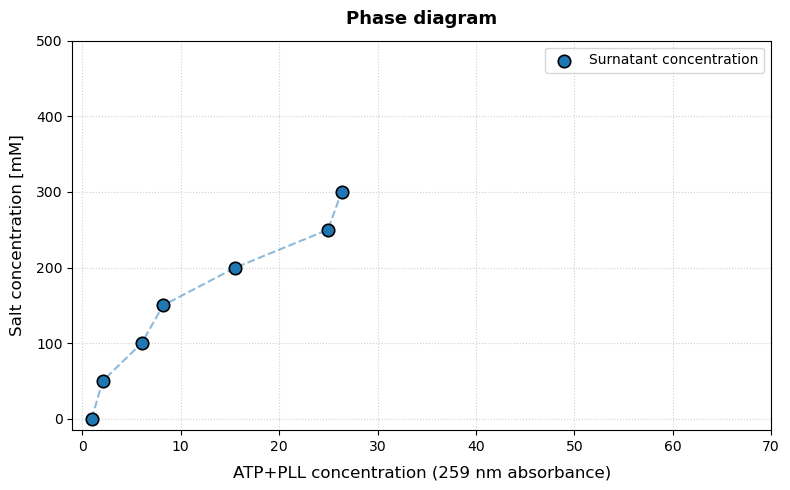

In [17]:
# Se hai un fattore di conversione da assorbanza a concentrazione (Legge di Lambert-Beer: A = ε * b * c),
# puoi impostarlo qui sotto. Di default usiamo direttamente i valori di ABSORBANCE (a 259 nm).
extinction_factor = 1.0  # es. epsilon * cammino_ottico
concentration = ABSORBANCE / extinction_factor

plt.figure(figsize=(8, 5), dpi=100)

# Scatter plot: Concentrazione sulle ascisse (X), Concentrazione di Sale sulle ordinate (Y)
plt.scatter(concentration, SALT, color="#1f77b4", s=80, edgecolors="black", linewidth=1.2, zorder=3, label="Surnatant concentration")

# Linea tratteggiata per visualizzare il trend del diagramma di fase (ordinato per sale)
sort_idx = np.argsort(SALT)
plt.plot(concentration[sort_idx], SALT[sort_idx], linestyle="--", color="#1f77b4", alpha=0.5, zorder=2)

# Dettagli del grafico
plt.xlabel("ATP+PLL concentration (259 nm absorbance)", fontsize=12, labelpad=8)
plt.ylabel("Salt concentration [mM]", fontsize=12, labelpad=8)
plt.title("Phase diagram", fontsize=13, fontweight="bold", pad=12)
plt.grid(True, linestyle=":", alpha=0.6, zorder=1)
plt.legend(frameon=True)
plt.xlim(-1, 70) 
plt.ylim(-15, 500) 
plt.tight_layout()

plt.show()
